# EDA and error analysis: building daily energy use (IFJC4002, Case 4)

Run from the project root or from `notebooks/`. Needs `data/processed/daily_energy.csv` and `models/`.
Every figure is saved to `docs/figures/` and the key numbers to `docs/figures/results.json`,
so the report can cite them.

In [1]:
import os, sys, json, time
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from src import config, train

FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = {}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
T = config.TARGET

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150); plt.show()

df = train.load_data(config.DATA_PATH)
df["eui"] = df[T] / df["floor_area_m2"]   # kWh per m2 per day, to compare buildings of different size
print(df.shape)

(92459, 8)


## 1. Dataset overview

In [2]:
RES["rows"] = len(df); RES["buildings"] = int(df.building_id.nunique())
RES["date_min"] = str(df.date.min().date()); RES["date_max"] = str(df.date.max().date())
per_b = df.groupby("building_id").size()
RES["rows_per_building_min"] = int(per_b.min()); RES["rows_per_building_max"] = int(per_b.max())
RES["missing_in_processed"] = df[config.FEATURES + [T]].isna().sum().to_dict()
display(df.head())
print(df.dtypes)
print("missing values:", RES["missing_in_processed"])
desc = df[[T, "floor_area_m2", "air_temp_c", "eui"]].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2)
display(desc)
RES["describe"] = desc.to_dict(orient="index")

,building_id,date,energy_kwh_day,floor_area_m2,air_temp_c,building_type,day_of_week,eui
0,Bear_education_Augusta,2016-01-01,1720.7,14017.9,6.2,Education,Friday,0.122750
1,Rat_education_Dreama,2016-01-01,2580.6,9801.3,5.6,Education,Friday,0.263292
2,Rat_education_Chance,2016-01-01,784.0,5592.8,5.6,Education,Friday,0.140180
3,Rat_education_Cedric,2016-01-01,1790.0,6169.1,5.6,Education,Friday,0.290156
4,Rat_education_Candida,2016-01-01,2884.7,3576.8,5.6,Education,Friday,0.806503


building_id                  str
date              datetime64[us]
energy_kwh_day           float64
floor_area_m2            float64
air_temp_c               float64
building_type                str
day_of_week                  str
eui                      float64
dtype: object
missing values: {'floor_area_m2': 0, 'air_temp_c': 0, 'building_type': 0, 'day_of_week': 0, 'energy_kwh_day': 0}


,count,mean,std,min,1%,25%,50%,75%,99%,max
energy_kwh_day,92459.0,3476.34,6030.31,1.00,15.00,499.30,1488.60,3770.20,28860.48,158149.20
floor_area_m2,92459.0,8361.55,10133.05,26.30,102.40,2043.90,5248.70,10431.40,51394.90,81290.10
air_temp_c,92459.0,15.67,9.75,-24.80,-9.20,9.00,16.40,23.20,35.80,40.50
eui,92459.0,0.47,0.71,0.01,0.01,0.18,0.31,0.54,3.05,22.14


In [3]:
# Raw-data quality, before building the daily table (skipped if the raw files are absent)
raw_e, raw_m = ROOT / "data/raw/electricity_cleaned.csv", ROOT / "data/raw/metadata.csv"
if raw_e.exists() and raw_m.exists():
    e = pd.read_csv(raw_e, index_col="timestamp")
    m = pd.read_csv(raw_m, usecols=["building_id", "primaryspaceusage", "sqm"])
    RES["raw_meters"] = int(e.shape[1]); RES["raw_hours"] = int(e.shape[0])
    RES["raw_hourly_missing_share"] = float(e.isna().to_numpy().mean())
    RES["raw_all_missing_meters"] = int(e.isna().all().sum())
    RES["meta_buildings"] = int(len(m))
    RES["meta_missing_sqm"] = int(m["sqm"].isna().sum())
    RES["meta_missing_type"] = int(m["primaryspaceusage"].isna().sum())
    print({k: v for k, v in RES.items() if k.startswith(("raw_", "meta_"))})
    del e

{'raw_meters': 1578, 'raw_hours': 17544, 'raw_hourly_missing_share': 0.0892867514854558, 'raw_all_missing_meters': 6, 'meta_buildings': 1636, 'meta_missing_sqm': 0, 'meta_missing_type': 21}


## 2. Target: distribution and unusual values

skew raw / log1p: 5.1 -0.53
{0.5: 1489.0, 0.9: 8952.0, 0.99: 28860.0, 0.999: 63673.0} | max 158149


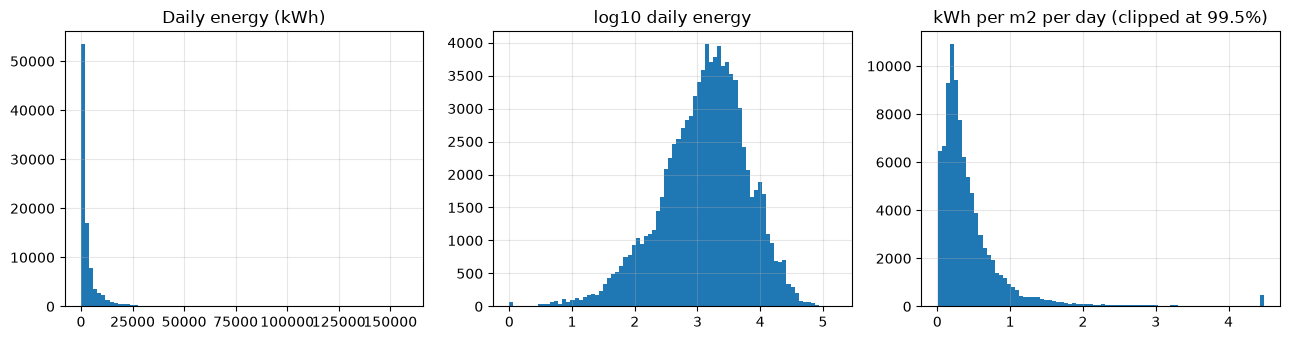

In [4]:
RES["target_skew"] = float(df[T].skew()); RES["target_log_skew"] = float(np.log1p(df[T]).skew())
q = df[T].quantile([.5, .9, .99, .999]); RES["target_quantiles"] = q.round(1).to_dict()
RES["eui_quantiles"] = df["eui"].quantile([.01, .5, .99, .999]).round(3).to_dict()
print("skew raw / log1p:", round(RES["target_skew"], 2), round(RES["target_log_skew"], 2))
print(q.round(0).to_dict(), "| max", round(df[T].max()))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].hist(df[T], bins=80); ax[0].set_title("Daily energy (kWh)")
ax[1].hist(np.log10(df[T]), bins=80); ax[1].set_title("log10 daily energy")
ax[2].hist(df["eui"].clip(upper=df["eui"].quantile(.995)), bins=80); ax[2].set_title("kWh per m2 per day (clipped at 99.5%)")
save("fig_target_distribution")

## 3. Features and their relation to the target

,rows,buildings,median_eui
building_type,,,
Education,35915,603,0.297
Office,17760,296,0.326
Entertainment/public assembly,11653,197,0.308
Public services,9900,165,0.395
Lodging/residential,8880,148,0.237
Healthcare,1620,27,0.474
Other,1560,26,0.362
Parking,1320,22,0.033
Warehouse/storage,791,14,0.311


C:\Users\Acer\AppData\Local\Temp\ipykernel_2936\12545814.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot([df.loc[df.building_type == t, "eui"] for t in order], vert=False, showfliers=False)


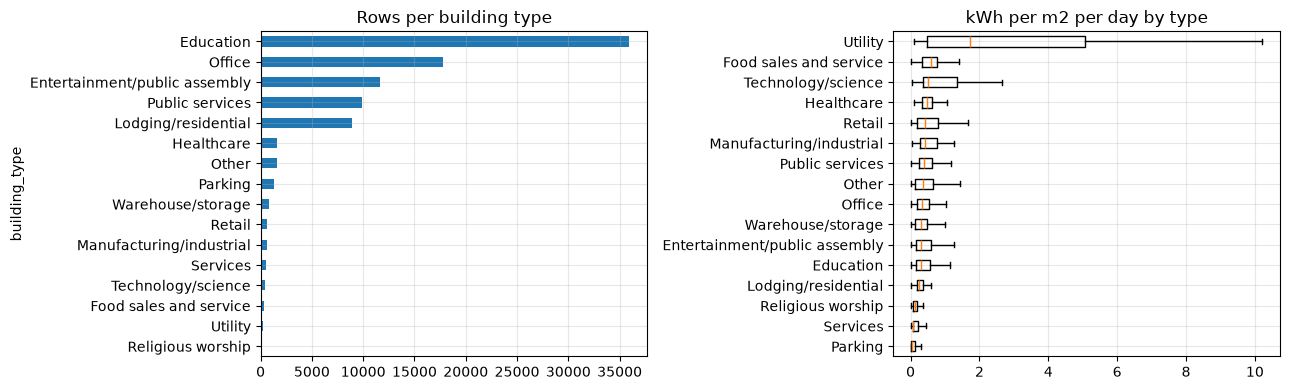

In [5]:
counts = df.groupby("building_type").agg(rows=(T, "size"), buildings=("building_id", "nunique"),
                                         median_eui=("eui", "median")).sort_values("rows", ascending=False)
display(counts.round(3)); RES["type_counts"] = counts.round(3).to_dict(orient="index")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts["rows"].sort_values().plot.barh(ax=ax[0]); ax[0].set_title("Rows per building type")
order = counts.sort_values("median_eui").index
ax[1].boxplot([df.loc[df.building_type == t, "eui"] for t in order], vert=False, showfliers=False)
ax[1].set_yticks(range(1, len(order) + 1)); ax[1].set_yticklabels(order); ax[1].set_title("kWh per m2 per day by type")
save("fig_building_type")

{'log_area_vs_energy': 0.7787799198951051, 'temp_vs_energy': 0.03732530029668378, 'temp_vs_eui': 0.11691847112971454}


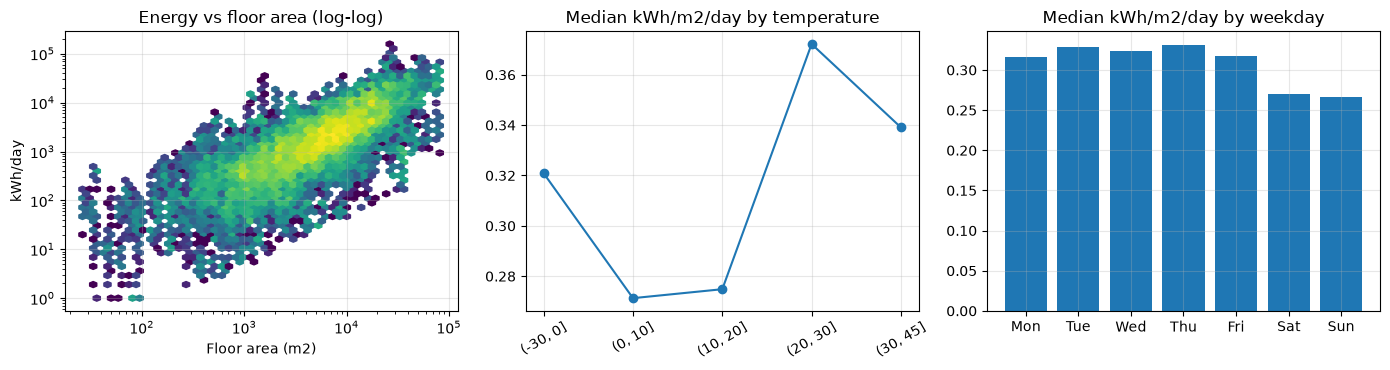

weekend/weekday EUI ratio: 0.829
{Interval(-30, 0, closed='right'): 0.321, Interval(0, 10, closed='right'): 0.271, Interval(10, 20, closed='right'): 0.275, Interval(20, 30, closed='right'): 0.372, Interval(30, 45, closed='right'): 0.339}


In [6]:
sp = lambda a, b: float(df[[a, b]].corr(method="spearman").iloc[0, 1])
RES["spearman"] = {"log_area_vs_energy": sp("floor_area_m2", T), "temp_vs_energy": sp("air_temp_c", T),
                   "temp_vs_eui": sp("air_temp_c", "eui")}
print(RES["spearman"])
dow = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dmed = df.groupby("day_of_week")["eui"].median().reindex(dow)
RES["eui_by_weekday"] = dmed.round(4).to_dict()
RES["weekend_vs_weekday_eui_ratio"] = float(dmed[["Saturday", "Sunday"]].mean() / dmed[dow[:5]].mean())
tb = pd.cut(df.air_temp_c, [-30, 0, 10, 20, 30, 45])
tmed = df.groupby(tb, observed=True)["eui"].median(); RES["eui_by_temp_bin"] = {str(k): round(float(v), 4) for k, v in tmed.items()}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hexbin(df.floor_area_m2, df[T], gridsize=50, xscale="log", yscale="log", bins="log", mincnt=1)
ax[0].set_xlabel("Floor area (m2)"); ax[0].set_ylabel("kWh/day"); ax[0].set_title("Energy vs floor area (log-log)")
ax[1].plot(range(len(tmed)), tmed.values, marker="o"); ax[1].set_xticks(range(len(tmed)))
ax[1].set_xticklabels([str(i) for i in tmed.index], rotation=30); ax[1].set_title("Median kWh/m2/day by temperature")
ax[2].bar(range(7), dmed.values); ax[2].set_xticks(range(7)); ax[2].set_xticklabels([d[:3] for d in dow]); ax[2].set_title("Median kWh/m2/day by weekday")
save("fig_feature_relations")
print("weekend/weekday EUI ratio:", round(RES["weekend_vs_weekday_eui_ratio"], 3))
print(tmed.round(3).to_dict())

## 4. Train/test split (by building)

In [7]:
tr, te = train.split(df)
RES["n_train"], RES["n_test"] = len(tr), len(te)
RES["buildings_train"], RES["buildings_test"] = int(tr.building_id.nunique()), int(te.building_id.nunique())
RES["building_overlap"] = len(set(tr.building_id) & set(te.building_id))
print({k: RES[k] for k in ["n_train", "n_test", "buildings_train", "buildings_test", "building_overlap"]})
share = pd.concat([tr.building_type.value_counts(normalize=True).rename("train"),
                   te.building_type.value_counts(normalize=True).rename("test")], axis=1).fillna(0).round(3)
display(share)
print("median area train/test:", tr.floor_area_m2.median(), te.floor_area_m2.median())
RES["median_area_train_test"] = [float(tr.floor_area_m2.median()), float(te.floor_area_m2.median())]

{'n_train': 73964, 'n_test': 18495, 'buildings_train': 1239, 'buildings_test': 310, 'building_overlap': 0}


,train,test
building_type,,
Education,0.385,0.403
Office,0.191,0.198
Entertainment/public assembly,0.128,0.117
Public services,0.111,0.091
Lodging/residential,0.101,0.078
Healthcare,0.018,0.016
Other,0.015,0.023
Parking,0.011,0.029
Warehouse/storage,0.009,0.006


median area train/test: 5132.0 5416.9


## 5. Model comparison (same split, same seed)

In [8]:
X_tr, y_tr, X_te, y_te = tr[config.FEATURES], tr[T], te[config.FEATURES], te[T]
meta = json.load(open(config.MODEL_DIR / "metadata.json"))
fitted, rows = {}, []
for name, mdl in train.candidate_models().items():
    pipe = Pipeline([("prep", train.build_preprocessor()), ("model", mdl)])
    t0 = time.perf_counter(); pipe.fit(X_tr, y_tr); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = pipe.predict(X_te); pred_s = time.perf_counter() - t0
    m = train.evaluate(y_te, pred)
    m.update({"median_abs_pct_error": float(np.median(np.abs(pred - y_te) / y_te) * 100),
              "MAE_pct_of_mean": float(m["MAE"] / y_te.mean() * 100),
              "fit_seconds": fit_s, "predict_ms_per_1000": pred_s / len(X_te) * 1e6})
    fitted[name] = (pipe, pred); rows.append({"model": name, **m})
comp = pd.DataFrame(rows).set_index("model")
cv = pd.DataFrame(meta["cv_results"]).T
comp = comp.join(cv)
display(comp.round(2)); RES["comparison"] = comp.round(4).to_dict(orient="index")
# the saved results must match this re-run
for name in comp.index:
    assert abs(comp.loc[name, "RMSE"] - meta["test_results"][name]["RMSE"]) < 1.0, name
print("re-run matches models/metadata.json")
saved = joblib.load(config.MODEL_DIR / "model.joblib")
print("saved model reproduces re-fit predictions:", np.allclose(saved.predict(X_te), fitted[meta["selected_model"]][1]))

,MAE,RMSE,R2,median_abs_pct_error,MAE_pct_of_mean,fit_seconds,predict_ms_per_1000,cv_RMSE_mean,cv_RMSE_std
model,,,,,,,,,
Baseline (train mean),3188.90,5133.98,-0.01,150.70,104.33,0.19,2.65,6134.84,1165.54
Ridge regression,1683.19,3523.61,0.52,49.84,55.07,0.31,1.96,4835.52,929.27
Random forest,1801.03,3707.16,0.47,50.71,58.92,8.45,10.11,4800.33,1047.75


re-run matches models/metadata.json
saved model reproduces re-fit predictions: True


## 6. Error analysis

mean error (bias): -284 | share overpredicted: 0.525 | median / p90 abs error: 698 5036


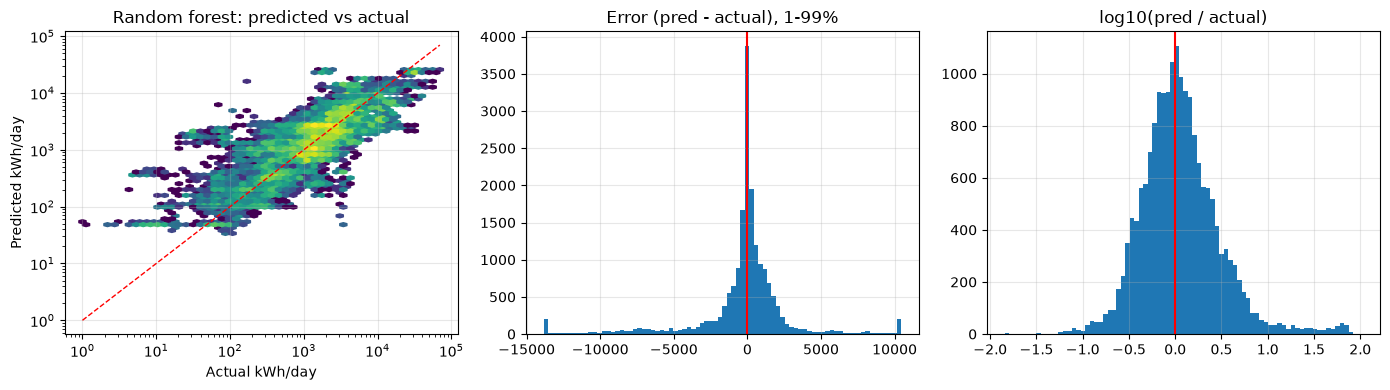

In [9]:
te = te.copy()
te["pred_rf"] = fitted["Random forest"][1]; te["pred_ridge"] = fitted["Ridge regression"][1]
te["err"] = te.pred_rf - te[T]; te["abs_err"] = te.err.abs()
RES["bias_mean_error_kwh"] = float(te.err.mean()); RES["share_overpredicted"] = float((te.err > 0).mean())
RES["median_abs_err"] = float(te.abs_err.median()); RES["p90_abs_err"] = float(te.abs_err.quantile(.9))
print("mean error (bias):", round(RES["bias_mean_error_kwh"]), "| share overpredicted:", round(RES["share_overpredicted"], 3),
      "| median / p90 abs error:", round(RES["median_abs_err"]), round(RES["p90_abs_err"]))
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
lim = [max(te[T].min(), 1), te[T].max()]
ax[0].hexbin(te[T].clip(lower=1), te.pred_rf.clip(lower=1), gridsize=50, xscale="log", yscale="log", bins="log", mincnt=1)
ax[0].plot(lim, lim, "r--", lw=1); ax[0].set_xlabel("Actual kWh/day"); ax[0].set_ylabel("Predicted kWh/day"); ax[0].set_title("Random forest: predicted vs actual")
ax[1].hist(te.err.clip(te.err.quantile(.01), te.err.quantile(.99)), bins=80); ax[1].set_title("Error (pred - actual), 1-99%"); ax[1].axvline(0, color="r")
ax[2].hist(np.log10(te.pred_rf.clip(lower=1) / te[T].clip(lower=1)), bins=80); ax[2].set_title("log10(pred / actual)"); ax[2].axvline(0, color="r")
save("fig_pred_vs_actual")


== by_type


,rows,buildings,mean_actual,MAE_rf,bias_rf,MAE_ridge,MAE_rf_pct_of_mean
building_type,,,,,,,
Education,7455,126,3903.3,2449.4,-96.0,2135.3,62.8
Office,3660,61,3182.6,1716.3,-54.3,1597.3,53.9
Entertainment/public assembly,2160,36,1849.0,1030.7,-463.1,1060.1,55.7
Public services,1680,28,3218.2,1753.3,-1404.6,1582.8,54.5
Lodging/residential,1440,24,1454.2,663.3,-120.4,605.1,45.6
Parking,540,9,1170.7,648.8,-362.4,2638.3,55.4
Other,420,7,450.4,435.0,194.2,435.1,96.6
Healthcare,300,5,5411.9,3113.8,626.4,2574.1,57.5
Retail,300,5,2800.2,1721.9,-1376.1,1601.0,61.5



== by_size


,rows,buildings,mean_actual,MAE_rf,bias_rf,MAE_ridge,MAE_rf_pct_of_mean
size_bin,,,,,,,
"(26.299, 1505.0]",3720,62,406.4,265.8,-154.6,271.7,65.4
"(1505.0, 4292.5]",3735,64,921.9,549.3,-37.3,508.8,59.6
"(4292.5, 6938.2]",3660,61,2167.7,1200.5,-422.5,1124.4,55.4
"(6938.2, 12683.3]",3720,62,3619.6,2220.4,-483.7,2149.7,61.3
"(12683.3, 63138.2]",3660,61,8245.3,4813.1,-327.2,4400.9,58.4



== by_temp


,rows,buildings,mean_actual,MAE_rf,bias_rf,MAE_ridge,MAE_rf_pct_of_mean
temp_bin,,,,,,,
"(-30, 0]",1096,157,4018.8,1885.7,-582.9,2017.7,46.9
"(0, 10]",4169,274,2784.8,1570.9,-288.0,1439.7,56.4
"(10, 20]",6551,308,2907.0,1869.8,-100.0,1621.9,64.3
"(20, 30]",5904,279,3256.5,1891.0,-506.4,1869.9,58.1
"(30, 45]",775,113,2899.7,1652.4,292.6,1616.2,57.0



== by_weekday


,rows,buildings,mean_actual,MAE_rf,bias_rf,MAE_ridge,MAE_rf_pct_of_mean
day_of_week,,,,,,,
Monday,2678,309,3232.2,1936.8,-356.8,1743.4,59.9
Tuesday,2585,309,3225.2,1808.2,-274.6,1723.6,56.1
Wednesday,2598,309,3070.2,1790.6,-408.0,1657.4,58.3
Thursday,2691,309,3101.2,1819.7,-330.0,1686.1,58.7
Friday,2616,309,3167.9,1834.3,-218.3,1702.0,57.9
Saturday,2668,309,2852.6,1739.5,-238.3,1662.3,61.0
Sunday,2659,310,2752.5,1677.7,-164.5,1608.0,61.0


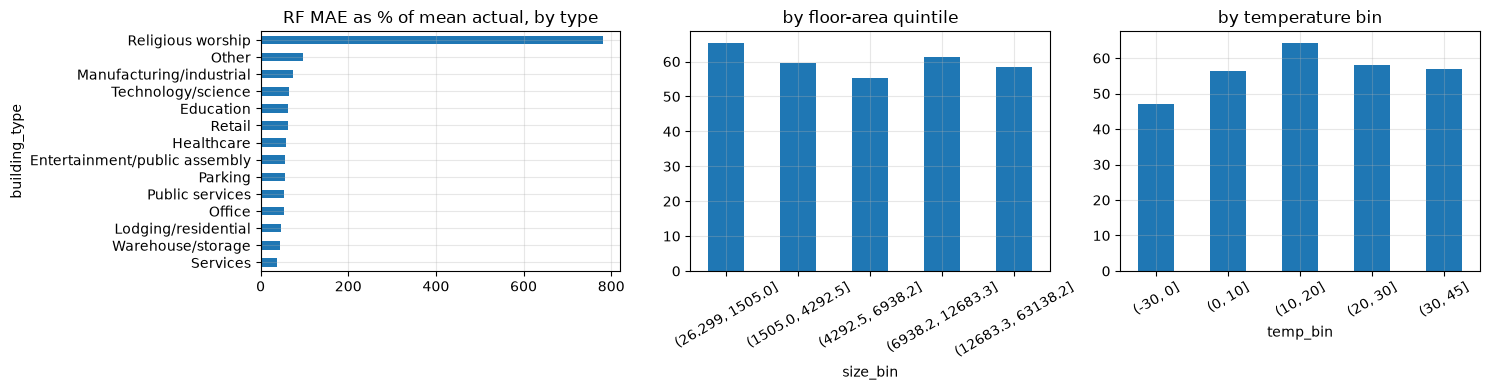

In [10]:
def grp(col):
    g = te.groupby(col, observed=True).agg(rows=(T, "size"), buildings=("building_id", "nunique"), mean_actual=(T, "mean"),
                                           MAE_rf=("abs_err", "mean"), bias_rf=("err", "mean"))
    g["MAE_ridge"] = te.assign(a=(te.pred_ridge - te[T]).abs()).groupby(col, observed=True)["a"].mean()
    g["MAE_rf_pct_of_mean"] = g.MAE_rf / g.mean_actual * 100
    return g
by_type = grp("building_type").sort_values("rows", ascending=False)
te["size_bin"] = pd.qcut(te.floor_area_m2, 5)
te["temp_bin"] = pd.cut(te.air_temp_c, [-30, 0, 10, 20, 30, 45])
by_size, by_temp, by_dow = grp("size_bin"), grp("temp_bin"), grp("day_of_week").reindex(dow)
for n, g in [("by_type", by_type), ("by_size", by_size), ("by_temp", by_temp), ("by_weekday", by_dow)]:
    print("\n==", n); display(g.round(1))
    RES[n] = {str(k): v for k, v in g.round(2).to_dict(orient="index").items()}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
by_type["MAE_rf_pct_of_mean"].sort_values().plot.barh(ax=ax[0]); ax[0].set_title("RF MAE as % of mean actual, by type")
by_size["MAE_rf_pct_of_mean"].plot.bar(ax=ax[1], rot=30); ax[1].set_title("by floor-area quintile")
by_temp["MAE_rf_pct_of_mean"].plot.bar(ax=ax[2], rot=30); ax[2].set_title("by temperature bin")
save("fig_error_by_group")

In [11]:
pb = te.groupby("building_id").agg(type=("building_type", "first"), area=("floor_area_m2", "first"),
                                   mean_actual=(T, "mean"), mae=("abs_err", "mean"), bias=("err", "mean")).sort_values("mae", ascending=False)
tot = (pb.mae * te.groupby("building_id").size().reindex(pb.index)).sum()
cum = (pb.mae * te.groupby("building_id").size().reindex(pb.index)).cumsum() / tot
k = max(int(len(pb) * 0.05), 1)
RES["top5pct_buildings_share_of_abs_error"] = float(cum.iloc[k - 1]); RES["n_test_buildings"] = len(pb)
print(f"top 5% of test buildings ({k}) carry {cum.iloc[k-1]:.1%} of total absolute error")
display(pb.head(10).round(0)); RES["worst_buildings"] = pb.head(10).round(1).reset_index().to_dict(orient="records")

top 5% of test buildings (15) carry 33.1% of total absolute error


,type,area,mean_actual,mae,bias
building_id,,,,,
Peacock_education_Karl,Education,44382.0,1918.0,21867.0,21867.0
Rat_public_Sana,Public services,37161.0,25740.0,18914.0,-17407.0
Rat_public_Alanna,Public services,42888.0,28298.0,15240.0,-15240.0
Gator_assembly_Blanca,Entertainment/public assembly,8574.0,17606.0,15128.0,-15128.0
Peacock_education_Ophelia,Education,11226.0,16822.0,13197.0,-13197.0
Hog_office_Cornell,Office,62385.0,36617.0,12123.0,-12116.0
Bull_office_Rob,Office,30885.0,6664.0,11196.0,11196.0
Moose_education_Maria,Education,36000.0,17509.0,10962.0,-10962.0
Wolf_education_Cheryl,Education,25605.0,3214.0,10721.0,10721.0


## 7. Feature importance (permutation, random forest, test sample)

air_temp_c          3.7
day_of_week         8.9
building_type     447.3
floor_area_m2    2522.2
dtype: float64

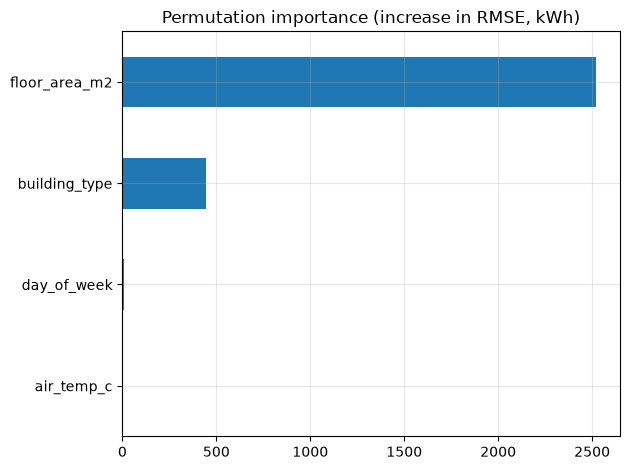

In [12]:
samp = te.sample(n=min(5000, len(te)), random_state=config.SEED)
pi = permutation_importance(fitted["Random forest"][0], samp[config.FEATURES], samp[T], n_repeats=5,
                            random_state=config.SEED, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=config.FEATURES).sort_values()
display(imp.round(1)); RES["permutation_importance_rmse_increase"] = imp.round(1).to_dict()
imp.plot.barh(title="Permutation importance (increase in RMSE, kWh)"); save("fig_feature_importance")

In [13]:
with open(FIG / "results.json", "w") as f:
    json.dump(RES, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved", FIG / "results.json", "|", sorted(p.name for p in FIG.glob("*.png")))

saved C:\UniMAP\energy-prediction\docs\figures\results.json | ['fig_building_type.png', 'fig_error_by_group.png', 'fig_feature_importance.png', 'fig_feature_relations.png', 'fig_pred_vs_actual.png', 'fig_target_distribution.png']
